In [1]:
import numpy as np 
import pandas as pd 
import matplotlib as plt

In [2]:
train_df = pd.read_csv('/kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_train.csv')
test_df = pd.read_csv('/kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_test.csv')

print(train_df.shape)
print(test_df.shape)
train_df.head()

(60000, 785)
(10000, 785)


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
X_train = train_df.drop(columns = ["label"]).to_numpy()
Y_train = train_df["label"].to_numpy()

X_test = test_df.drop(columns = ["label"]).to_numpy()
Y_test = test_df["label"].to_numpy()

print(X_train.shape, Y_train.shape)
print(X_test.shape, Y_test.shape)

(60000, 784) (60000,)
(10000, 784) (10000,)


In [4]:
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_val, Y_train, Y_val = train_test_split(
    X_train,
    Y_train,
    test_size=0.1,
    random_state=42,
    stratify=Y_train
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (54000, 784)
Validation: (6000, 784)
Testing: (10000, 784)


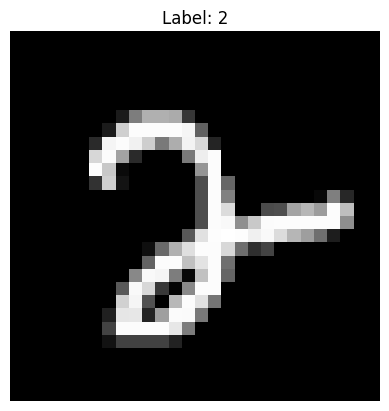

In [6]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0].reshape(28, 28), cmap="gray")
plt.title(f"Label: {Y_train[0]}")
plt.axis("off")
plt.show()

In [7]:
def init_params():
    rng = np.random.default_rng(42)

    W1 = rng.standard_normal((784, 128)) * np.sqrt(2 / 784)
    b1 = np.zeros((1, 128))

    W2 = rng.standard_normal((128, 64)) * np.sqrt(2 / 128)
    b2 = np.zeros((1, 64))

    W3 = rng.standard_normal((64, 10)) * np.sqrt(2 / 64)
    b3 = np.zeros((1, 10))

    parameters = {
        "W1": W1, "b1": b1,
        "W2": W2, "b2": b2,
        "W3": W3, "b3": b3
    }

    return parameters

parameters = init_params()

In [8]:
def ReLU(Z):
    return np.maximum(0, Z)

def Softmax(Z):
    Z_stable = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z_stable)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

def forward_prop(X, parameters):
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]
    W3, b3 = parameters["W3"], parameters["b3"]
    Z1 = X @ W1 + b1
    A1 = ReLU(Z1)
    Z2 = A1 @ W2 + b2
    A2 = ReLU(Z2)
    Z3 = A2 @ W3 + b3
    A3 = Softmax(Z3)
    return Z1, A1, Z2, A2, Z3, A3

In [9]:
def Cat_Cross_Entropy(A3, y):
    m = len(y)
    correct_probs = A3[np.arange(m), y]
    correct_probs = np.clip(correct_probs, 1e-15, 1.0)
    L = -np.mean(np.log(correct_probs))
    return L

In [10]:
def driv_ReLU(Z):
    return Z > 0
    
def backward_prop(Z1, A1, Z2, A2, Z3, A3, X, Y, parameters):
    W2 = parameters["W2"]
    W3 = parameters["W3"]
    m = Y.size
    dz3 = A3.copy()
    dz3[np.arange(m), Y] -= 1
    dW3 = (A2.T @ dz3) / m
    db3 = np.sum(dz3, axis=0, keepdims=True) / m
    dz2 = (dz3 @ W3.T) * driv_ReLU(Z2)
    dW2 = (A1.T @ dz2) / m
    db2 = np.sum(dz2, axis=0, keepdims=True) / m
    dz1 = (dz2 @ W2.T) * driv_ReLU(Z1)
    dW1 = (X.T @ dz1) / m
    db1 = np.sum(dz1, axis=0, keepdims=True) / m
    return dW1, db1, dW2, db2, dW3, db3

In [11]:
def update_parameters(parameters, dW1, db1, dW2, db2, dW3, db3, alpha):
    parameters["W1"] -= alpha * dW1
    parameters["b1"] -= alpha * db1

    parameters["W2"] -= alpha * dW2
    parameters["b2"] -= alpha * db2

    parameters["W3"] -= alpha * dW3
    parameters["b3"] -= alpha * db3

    return parameters

In [12]:

import numpy as np

epochs = 20
batch_size = 64
alpha = 0.01

parameters = init_params()

# Store metrics for every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(epochs):

    # Shuffle training data
    indices = np.random.permutation(len(X_train))
    X_shuffled = X_train[indices]
    Y_shuffled = Y_train[indices]

    epoch_loss = 0.0

    # Mini-batch training
    for start in range(0, len(X_train), batch_size):
        X_batch = X_shuffled[start:start + batch_size]
        Y_batch = Y_shuffled[start:start + batch_size]

        # Forward propagation
        Z1, A1, Z2, A2, Z3, A3 = forward_prop(
            X_batch, parameters
        )

        # Calculate batch loss
        batch_loss = Cat_Cross_Entropy(A3, Y_batch)
        epoch_loss += batch_loss * len(X_batch)

        # Backpropagation
        grads = backward_prop(
            Z1, A1, Z2, A2, Z3, A3,
            X_batch, Y_batch, parameters
        )

        dW1, db1, dW2, db2, dW3, db3 = grads

        # Update parameters
        parameters = update_parameters(
            parameters,
            dW1, db1, dW2, db2, dW3, db3,
            alpha
        )

    # Average training loss across all samples
    train_loss = epoch_loss / len(X_train)

    # Evaluate training data after the epoch
    train_probs = forward_prop(X_train, parameters)[-1]
    train_loss_eval = Cat_Cross_Entropy(train_probs, Y_train)
    train_preds = np.argmax(train_probs, axis=1)
    train_acc = np.mean(train_preds == Y_train) * 100

    # Evaluate validation data (no parameter updates)
    val_probs = forward_prop(X_val, parameters)[-1]
    val_loss = Cat_Cross_Entropy(val_probs, Y_val)
    val_preds = np.argmax(val_probs, axis=1)
    val_acc = np.mean(val_preds == Y_val) * 100

    # Save metrics
    history["train_loss"].append(train_loss_eval)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss_eval:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )


Epoch 1/20 | Train Loss: 0.4132 | Val Loss: 0.4214 | Train Acc: 88.66% | Val Acc: 88.47%
Epoch 2/20 | Train Loss: 0.3199 | Val Loss: 0.3308 | Train Acc: 90.85% | Val Acc: 90.70%
Epoch 3/20 | Train Loss: 0.2836 | Val Loss: 0.2983 | Train Acc: 91.99% | Val Acc: 91.72%
Epoch 4/20 | Train Loss: 0.2528 | Val Loss: 0.2721 | Train Acc: 92.72% | Val Acc: 92.42%
Epoch 5/20 | Train Loss: 0.2310 | Val Loss: 0.2514 | Train Acc: 93.34% | Val Acc: 93.13%
Epoch 6/20 | Train Loss: 0.2148 | Val Loss: 0.2386 | Train Acc: 93.74% | Val Acc: 93.33%
Epoch 7/20 | Train Loss: 0.1998 | Val Loss: 0.2249 | Train Acc: 94.27% | Val Acc: 93.83%
Epoch 8/20 | Train Loss: 0.1916 | Val Loss: 0.2218 | Train Acc: 94.38% | Val Acc: 93.83%
Epoch 9/20 | Train Loss: 0.1760 | Val Loss: 0.2045 | Train Acc: 94.95% | Val Acc: 94.15%
Epoch 10/20 | Train Loss: 0.1645 | Val Loss: 0.1947 | Train Acc: 95.31% | Val Acc: 94.55%
Epoch 11/20 | Train Loss: 0.1549 | Val Loss: 0.1869 | Train Acc: 95.57% | Val Acc: 94.75%
Epoch 12/20 | Train

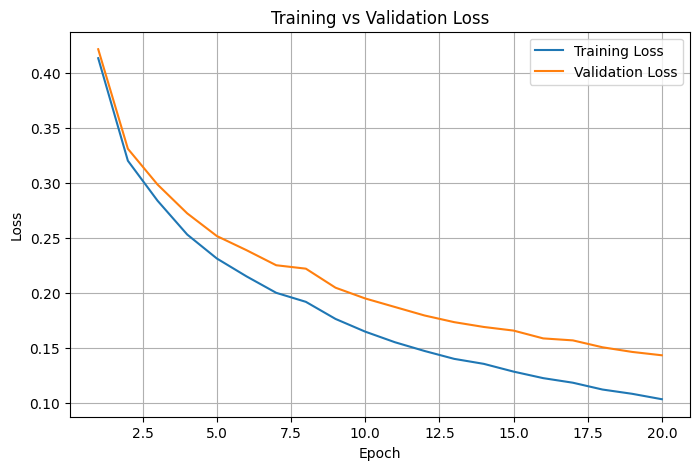

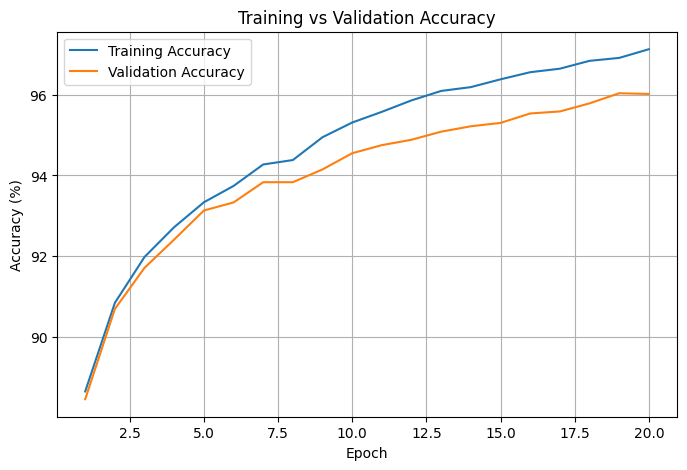

In [13]:

import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

# Loss curves
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_loss"], label="Training Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy curves
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_acc"], label="Training Accuracy")
plt.plot(epochs_range, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [14]:

def predict(X, parameters):
    Z1, A1, Z2, A2, Z3, A3 = forward_prop(X, parameters)
    return np.argmax(A3, axis=1)

def accuracy(X, Y, parameters):
    Y_pred = predict(X, parameters)
    return np.mean(Y_pred == Y) * 100

In [15]:
train_acc = accuracy(X_train, Y_train, parameters)
val_acc = accuracy(X_val, Y_val, parameters)

print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")

Training Accuracy: 97.12%
Validation Accuracy: 96.02%


In [16]:
test_acc = accuracy(X_test, Y_test, parameters)
print(f"Test Accuracy: {test_acc:.2f}%")

Test Accuracy: 96.58%


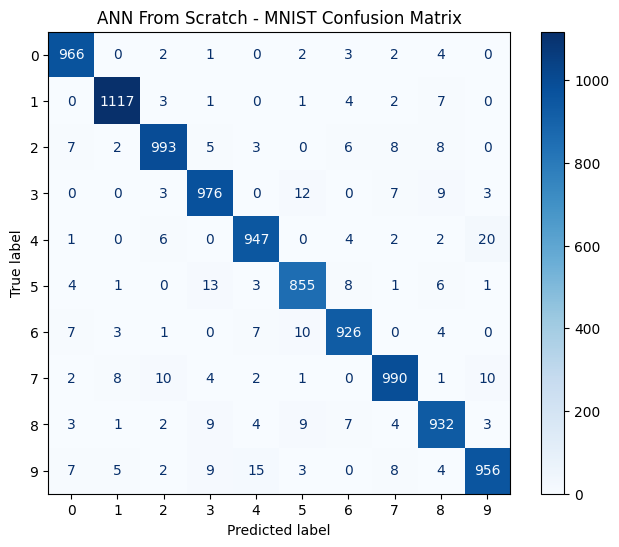

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

Y_pred = predict(X_test, parameters)

cm = confusion_matrix(Y_test, Y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("ANN From Scratch - MNIST Confusion Matrix")
plt.show()
